# Baum et al.: retention-curve comparison

This notebook checks the water-retention relation used by `unsatstab`. The plot compares the model relation with approximate points digitized from Figure 4 of Baum, Godt, and Savage (2010). **Figure 9 from Baum et al. (2008)** is embedded in a separate text cell immediately below the calculated plot, using the documentation asset. This is a component-level comparison: it checks the relation between pressure head and water content, not the transient solver or a full slope-stability application.

The digitized points are approximate visual readings from a published graph. They are not the original laboratory measurements. Agreement is a useful check on the constitutive curve, not full-model or field validation.

## Relation and parameters

Use the [intrinsic Gardner retention law](/unsatstab/fundamentals/#gardner-constitutive-laws-and-parameters), with pressure head $\psi$ in metres, Gardner parameter $\alpha=3.5$ m⁻¹, saturated water content $\theta_{\mathrm{s}}=0.41$, and residual water content $\theta_{\mathrm{r}}=0.05$ (both in m³/m³). The pressure offset is zero.

This standalone curve uses intrinsic $\alpha$, rather than the slope-adjusted flow coefficient. The published figures also discuss shifted capillary-fringe conventions, so equal material parameters do not by themselves establish equal pressure origins. The pressure axis is reversed to put saturation at the left, as in the reference figures.


In [1]:
%matplotlib inline
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import tol_colors as tc
import unsatstab as us

mpl.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 8.5,
    "mathtext.fontset": "dejavuserif",
    "axes.titlesize": 9,
    "axes.labelsize": 8.5,
    "axes.linewidth": 1.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "axes.grid": False,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "legend.frameon": False,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
})
COLORS = tc.colorsets["bright"]
TIME_CMAP = tc.colormaps["rainbow_PuBr"]
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "unsatstab").is_dir())
ASSET_DIR = REPO / "docs" / "assets"

from IPython.display import Image, Markdown, display


In [2]:
alpha_m_inv = 3.5
theta_s = 0.41
theta_r = 0.05
pressure_head_m = np.linspace(-1.8, 0.0, 500)
theta_model = us.gardner_water_content(
    pressure_head_m,
    alpha=alpha_m_inv,
    theta_s=theta_s,
    theta_r=theta_r,
)

# Approximate values digitized from the published graph for visual comparison.
pressure_head_reference_m = np.array([
    -0.002, -0.060, -0.067, -0.090, -0.107, -0.158,
    -0.209, -0.312, -0.411, -1.025, -1.363,
])
theta_reference = np.array([
    0.409, 0.409, 0.399, 0.374, 0.348, 0.293,
    0.169, 0.099, 0.094, 0.059, 0.049,
])


## Compare model and published curve

The open symbols distinguish the continuous model curve from approximate readings of Baum et al. (2010), Figure 4. Figure 9 from Baum et al. (2008) is embedded separately below the plotted results. Differences between the plots can reflect figure resolution and plotting conventions as well as the model relation.


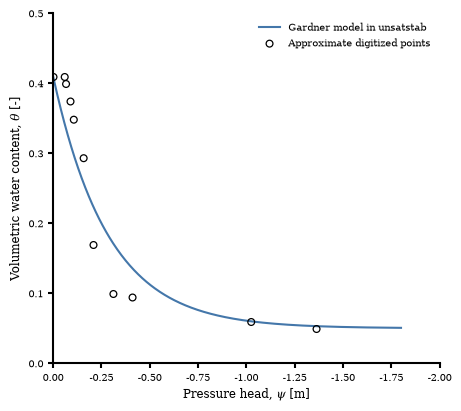

RMSE against approximate digitized points: 0.049


In [3]:
fig, ax = plt.subplots(figsize=(4.5, 4.0), constrained_layout=True)
ax.plot(
    pressure_head_m, theta_model,
    color=COLORS[0], linewidth=1.5,
    label="Gardner model in unsatstab",
)
ax.scatter(
    pressure_head_reference_m, theta_reference,
    facecolors="none", edgecolors="black", linewidths=0.9,
    s=24, zorder=3, label="Approximate digitized points",
)
ax.set(
    xlim=(0.0, -2.0),
    ylim=(0.0, 0.5),
    xlabel=r"Pressure head, $\psi$ [m]",
    ylabel=r"Volumetric water content, $\theta$ [-]",
)
ax.legend(loc="best")

plt.show()

residual = us.gardner_water_content(
    pressure_head_reference_m,
    alpha=alpha_m_inv,
    theta_s=theta_s,
    theta_r=theta_r,
) - theta_reference
print(f"RMSE against approximate digitized points: {np.sqrt(np.mean(residual**2)):.3f}")


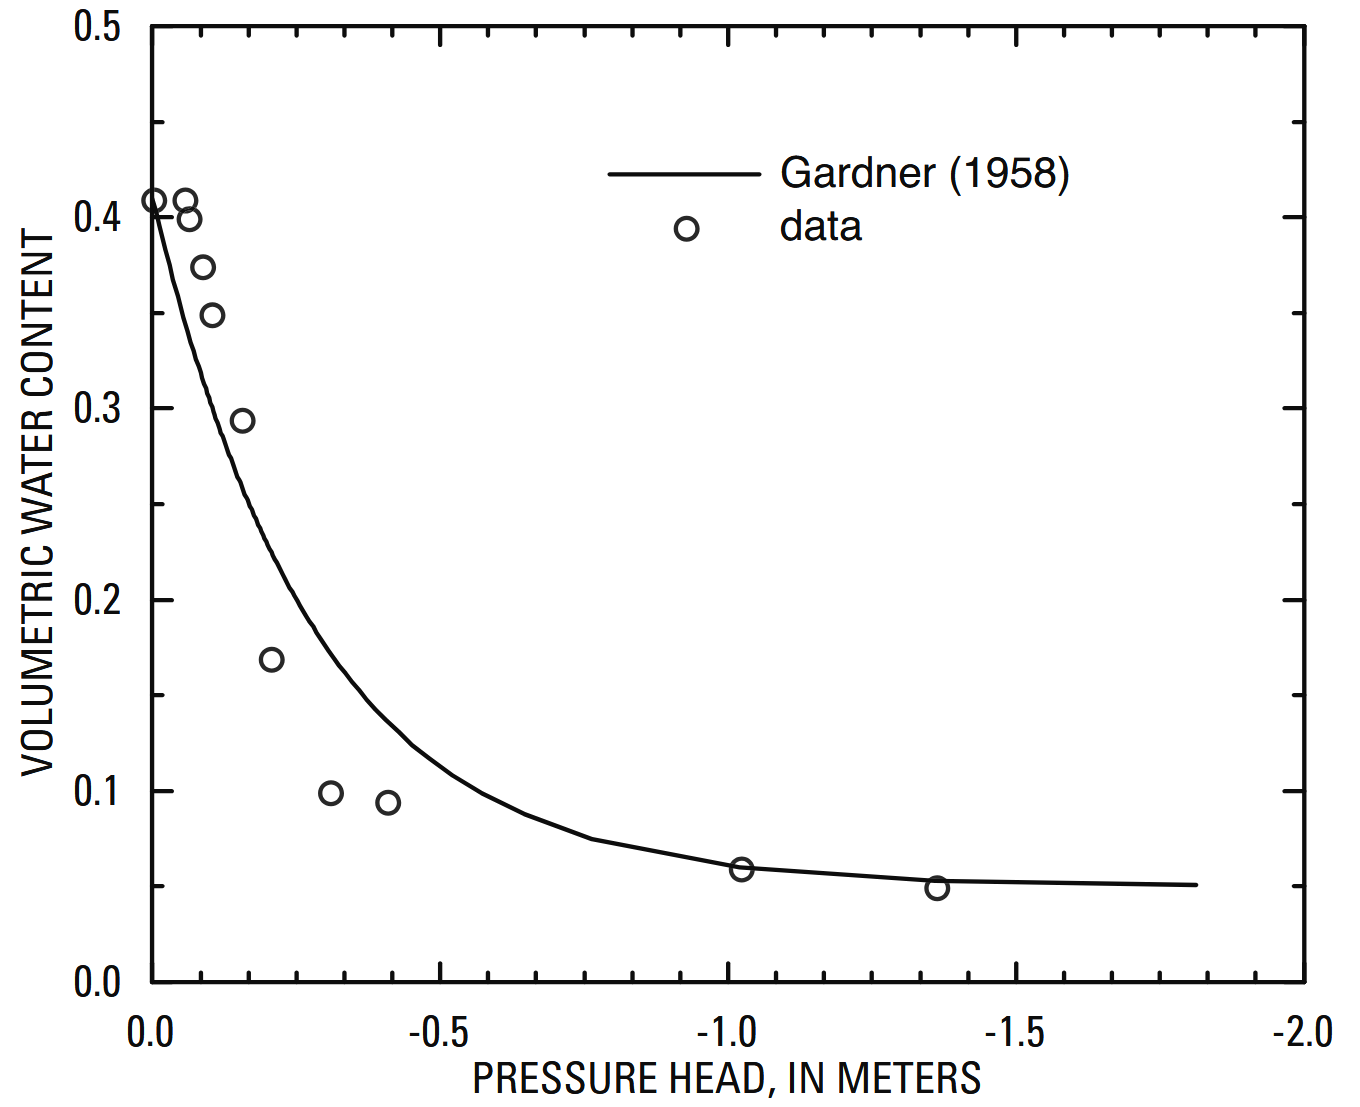

*Reference: Baum et al. (2008), Figure 9. The digitized points in that curve come from Baum et al. (2010), Figure 4.*


In [4]:
display(Image(filename=str(ASSET_DIR / "Figure_9_Baum_etal_2008.png"), width=450))
display(Markdown('*Reference: Baum et al. (2008), Figure 9. The digitized points in that curve come from Baum et al. (2010), Figure 4.*\n'))

## Interpretation and scope

This comparison supports the Gardner relation and its parameterization for the reference example. It does not verify time stepping, basal flux, water-table rise, or factor of safety. Those behaviors are addressed by the [space-time verification notebook](/unsatstab/verification/03_baum_etal_space_time/), where the `unsatstab` profiles are compared with Figure 10 of Baum et al. (2010).